# 手写数字识别示例
20250429更新版，适配mo平台

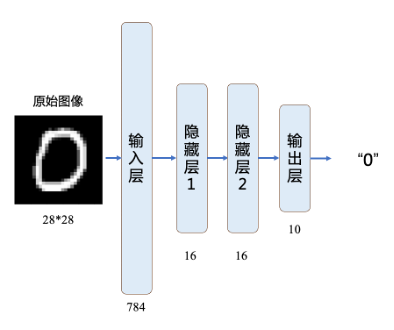

## 第一种方法：用上述图示的全连接网络，第一个隐藏层有16个神经元，第二个有16个神经元，输出层有10个神经元

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense, Flatten
from keras.utils import to_categorical
from keras.optimizers import Adam

In [4]:
#加载MNIST数据集
(x_train, y_train), (x_test, y_test) = mnist.load_data()

#数据归一化 (0-255 -> 0-1)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [5]:
print("X_train original shape", x_train.shape)
print("y_train original shape", y_train.shape)

X_train original shape (60000, 28, 28)
y_train original shape (60000,)


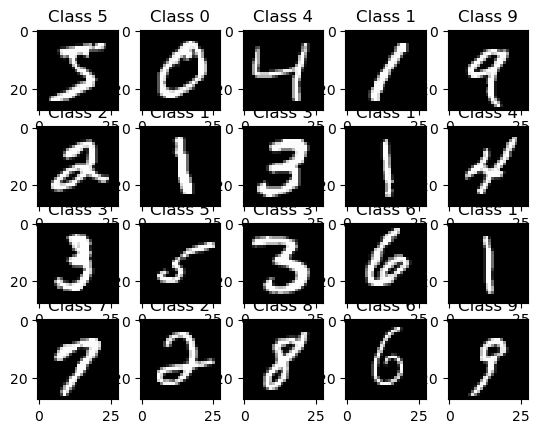

In [6]:
for i in range(20):
    plt.subplot(4,5,i+1)
    plt.imshow(x_train[i], cmap='gray', interpolation='none')
    plt.title("Class {}".format(y_train[i]))

In [7]:
# 将标签转换为one-hot编码
# 0 -> [1, 0, 0, 0, 0, 0, 0, 0, 0]
# 1 -> [0, 1, 0, 0, 0, 0, 0, 0, 0]
# 2 -> [0, 0, 1, 0, 0, 0, 0, 0, 0]
# etc.
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

In [8]:
# 3. 构建模型

model = Sequential() #创建空模型

model.add(Flatten(input_shape=(28,28))) # 展平层，将28x28图像转为784维向量
model.add(Dense(16, activation='relu')) # 第一个隐藏层，16个神经元
model.add(Dense(16, activation='relu')) # 第二个隐藏层，16个神经元
model.add(Dense(10, activation='softmax')) # 输出层，10个神经元对应10个数字类别

C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │          12,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             170 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,002 (50.79 KB)

 Trainable params: 13,002 (50.79 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# 4. 编译模型

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [11]:
# 5. 训练模型

history = model.fit(x_train, y_train_onehot,
                    batch_size=32,
                    epochs=10,
                    validation_split=0.2, #使用20%训练数据作为验证集
                    verbose=1)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.7125 - loss: 0.9058 - val_accuracy: 0.9345 - val_loss: 0.2403
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9320 - loss: 0.2419 - val_accuracy: 0.9443 - val_loss: 0.1988
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.9448 - loss: 0.1969 - val_accuracy: 0.9491 - val_loss: 0.1814
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9498 - loss: 0.1770 - val_accuracy: 0.9514 - val_loss: 0.1710
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 12ms/step - accuracy: 0.9536 - loss: 0.1591 - val_accuracy: 0.9537 - val_loss: 0.1657
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.9568 - loss: 0.1495 - val_accuracy: 0.9523 - val_loss: 0.1678
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.9595 - loss: 0.1434 - val_accuracy: 0.9513 - val_loss: 0.1639
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 24s 16ms/step - accuracy: 0.9589 - 

In [12]:
# 6. 评估模型

# 在测试集上评估
test_loss, test_acc = model.evaluate(x_test, y_test_onehot, verbose=0)
print(f"\n测试集准确率：{test_acc:.4f}")


测试集准确率：0.9505


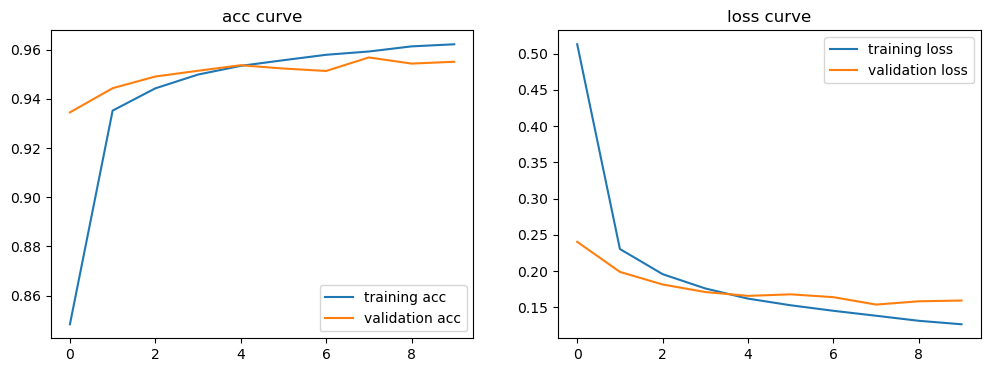

In [13]:
# 7. 绘制学习曲线

# 绘制训练曲线
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],label='training acc')
plt.plot(history.history['val_accuracy'],label='validation acc')
plt.title('acc curve')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label='validation loss')
plt.title('loss curve')
plt.legend()
plt.show()

In [14]:
# 分类器model根据每个输入示例的输出概率最高的类别predicted_classes
predict_x = model.predict(x_test)
predicted_classes = np.argmax(predict_x,axis=1)
# 检查哪些图片我们做对了/错了
correct_indices = np.nonzero(predicted_classes == y_test)[0]
incorrect_indices = np.nonzero(predicted_classes != y_test)[0]
print("做对的图片", correct_indices, f"共{len(correct_indices)}")
print("做错的图片", incorrect_indices, f"共{len(incorrect_indices)}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
做对的图片 [   0    1    2 ... 9997 9998 9999] 共9505
做错的图片 [   8   18   66  217  233  247  259  268  318  321  340  352  362  386
  391  403  412  445  448  465  495  531  532  536  543  565  582  591
  659  684  691  707  717  720  740  786  800  810  839  844  877  881
  882  938  947  950  951  956  965 1003 1014 1032 1039 1044 1062 1093
 1107 1112 1119 1125 1128 1181 1182 1194 1198 1202 1206 1226 1228 1232
 1242 1247 1248 1260 1267 1279 1283 1289 1319 1325 1326 1364 1378 1413
 1414 1425 1464 1467 1500 1522 1523 1527 1530 1549 1553 1569 1587 1609
 1634 1663 1671 1678 1681 1709 1717 1732 1737 1740 1751 1754 1773 1782
 1790 1819 1822 1828 1850 1878 1901 1938 1941 1952 1970 1982 1984 2004
 2016 2035 2040 2043 2044 2052 2053 2093 2098 2099 2109 2110 2118 2125
 2129 2130 2135 2182 2185 2186 2189 2233 2266 2272 2293 2298 2325 2339
 2369 2371 2381 2387 2393 2395 2406 2408 2414 2422 2423 2425 2433 2447
 2454 2462 2464 2488 2545 2560 2607 2610 2648 2654 2

部分分类正确的图片
部分分类错误的图片


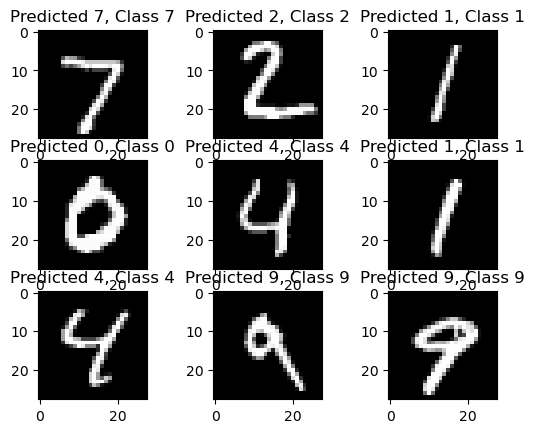

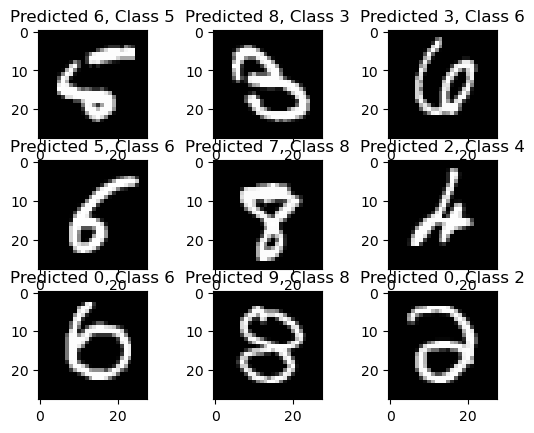

In [15]:
print("部分分类正确的图片")
plt.figure()
for i, correct in enumerate(correct_indices[:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[correct].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("Predicted {}, Class {}".format(predicted_classes[correct], y_test[correct]))

print("部分分类错误的图片")
plt.figure()
for i, incorrect in enumerate(incorrect_indices[:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[incorrect].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("Predicted {}, Class {}".format(predicted_classes[incorrect], y_test[incorrect]))

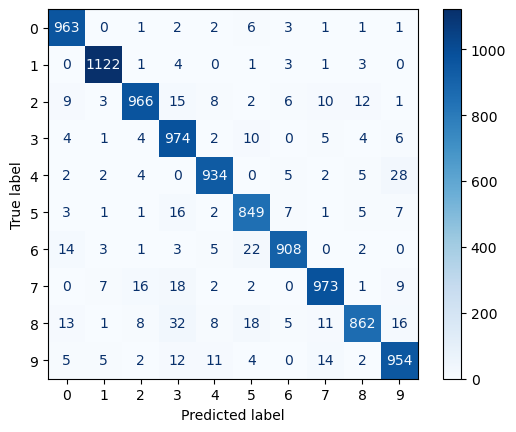

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predicted_classes)
labels = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp.plot(cmap=plt.cm.Blues)
plt.show()

## 第二种方法：用CNN实现

In [77]:
from keras import layers
CNN_model = Sequential() # 初试一个前馈神经网络

# 增加卷积运算层1， 卷积核数量=32个，卷积核大小3*3，激活函数relu
CNN_model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)))

# 增加池化层1，窗口（感受野）2*2
CNN_model.add(layers.MaxPooling2D((2,2)))

# 增加卷积运算层2，卷积核数量=64个，卷积核大小3*3，激活函数relu
CNN_model.add(layers.Conv2D(64, (3,3), activation='relu'))

# 增加池化层2，池化窗口（感受野）2*2
CNN_model.add(layers.MaxPooling2D((2,2)))

# 增加卷积运算层3，卷积核数量=64个，卷积核大小3*3，激活函数relu
CNN_model.add(layers.Conv2D(64, (3,3), activation='relu'))

# 添加全连接层，即MLP
CNN_model.add(layers.Flatten())
CNN_model.add(layers.Dense(64, activation='relu'))
CNN_model.add(layers.Dense(10, activation='softmax'))

C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [79]:
# 编译模型
CNN_model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

In [81]:
# 训练模型
print("大概需要一个小时，去看会教材吧")
x_train = x_train.reshape(-1, 28, 28, 1)
CNN_model.fit(x_train, y_train_onehot, epochs=1, batch_size=128)

大概需要一个小时，去看会教材吧
469/469 ━━━━━━━━━━━━━━━━━━━━ 33s 62ms/step - accuracy: 0.8265 - loss: 0.5475


In [82]:
# 评估模型
x_test = x_test.reshape(-1, 28, 28, 1)
test_loss, test_acc = CNN_model.evaluate(x_test, y_test_onehot)
print("测试准确率", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9776 - loss: 0.0688
测试准确率 0.9804999828338623


# 波士顿房价预测

波士顿房价数据集（Boston Housing Dataset）是一个非常著名的数据集，广泛用于回归分析和机器学习的入门研究。它最初由哈里森和鲁宾菲尔德（Harrison, D. and Rubinfeld, D.L.）在1978年发布，包含了波士顿地区房价的中位数与各种影响房价的因素。

这个数据集包含506个数据点，每个数据点有14个属性。

**输入属性（13种）：**

CRIM：城镇人均犯罪率。

ZN：住宅用地超过25000 sq.ft. 的比例。

INDUS：城镇非零售商用土地的比例。

CHAS：查尔斯河虚拟变量（如果边界是河流，则为1；否则为0）。

NOX：一氧化氮浓度（每千万份）。

RM：住宅平均房间数。

AGE：1940年之前建成的自用房屋比例。

DIS：到五个波士顿就业中心的加权距离。

RAD：辐射性公路的接近指数。

TAX：每10000美元的全值财产税率。

PTRATIO：城镇师生比例。

B：$1000(B_k - 0.63)^2$ 其中$B_k$为城镇中黑人的比例。

LSTAT：人口中地位较低人群的百分比。

**预测目标：**

MEDV：自有住房的中位数价值（单位：千美元）。

## 用全连接网络实现

In [28]:
from keras.datasets import boston_housing #导入波士顿房价数据集
from keras.models import Sequential #顺序模型
from keras.layers import Dense
from sklearn.preprocessing import StandardScaler

In [30]:
(train_x, train_y), (test_x, test_y) = boston_housing.load_data()

print(train_x.shape)
print(test_x.shape)
print(train_y.shape)
print(test_y.shape)
print(train_x[0])

(404, 13)
(102, 13)
(404,)
(102,)
[  1.23247   0.        8.14      0.        0.538     6.142    91.7
   3.9769    4.      307.       21.      396.9      18.72   ]


In [32]:
sc = StandardScaler()
train_x = sc.fit_transform(train_x)
test_x = sc.fit_transform(test_x)
print(train_x[0])
print(test_x[0])

[-0.27224633 -0.48361547 -0.43576161 -0.25683275 -0.1652266  -0.1764426
  0.81306188  0.1166983  -0.62624905 -0.59517003  1.14850044  0.44807713
  0.8252202 ]
[ 2.8040301  -0.50784934  0.96960877 -0.32969024  1.23174581  0.11934137
  1.14739788 -0.91935276  1.60609286  1.40778227  0.90513041 -4.27829517
  2.51324773]


In [34]:
FC_model = Sequential()#先建立一个顺序模型
#向顺序模型里加入第一个隐藏层，第一层一定要有一个输入数据的大小，需要有input_shape参数
#model.add(Dense(n_hidden_1, activation='relu', input_shape=(13,)))
FC_model.add(Dense(64, activation='relu', input_dim=13)) #这个input_dim和input_shape一样，就是少了括号和逗号
FC_model.add(Dense(64, activation='relu'))
FC_model.add(Dense(1)) #因为我们是预测房价，不是分类，所以最后一层可以不用激活函数

C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
FC_model.compile(loss='mse', optimizer=Adam(learning_rate=0.001), metrics=['mae'])
#因为我们这是预测房价，一个线性回归预测，所以loss跟分类是不一样的。
#我们这里要用mean_squared_error 可简写成mse optimizer
#我这里用rmsprop大家可以用adam其它梯度下降优化函数，
#正确率我们这里用mae平均绝对误差

In [38]:
#训练神经网络
history = FC_model.fit(train_x, train_y, batch_size=10, epochs=20)

Epoch 1/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 520.6642 - mae: 20.7991
Epoch 2/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 277.7874 - mae: 13.8322
Epoch 3/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 94.0057 - mae: 7.1756
Epoch 4/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 67.3445 - mae: 5.5761
Epoch 5/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 32.0478 - mae: 4.0569
Epoch 6/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 26.3342 - mae: 3.5818
Epoch 7/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 21.9957 - mae: 3.3717
Epoch 8/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 24.4723 - mae: 3.4221
Epoch 9/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 21.1389 - mae: 3.2237
Epoch 10/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 15.2525 - mae: 2.7391
Epoch 11/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 13.6826 - mae: 2.7625
Epoch 12/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 11.7211 - mae: 2.5373
Epoch 13/20
41/41 ━━━━━━━━━━━━━━

In [39]:
# 预测
pred_test_y = FC_model.predict(test_x)
print("预测结果", pred_test_y.tolist())

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step
预测结果 [[8.678726196289062], [18.751995086669922], [22.373096466064453], [30.85810089111328], [26.75942611694336], [18.6015567779541], [26.23145294189453], [22.7171630859375], [20.52878189086914], [21.368183135986328], [19.240718841552734], [17.578998565673828], [17.180706024169922], [42.52789306640625], [14.96220874786377], [19.26453971862793], [28.105913162231445], [21.32835578918457], [18.232316970825195], [24.026203155517578], [9.086477279663086], [15.005738258361816], [21.343067169189453], [15.606836318969727], [21.282642364501953], [23.57181167602539], [28.53289031982422], [29.47286605834961], [11.069141387939453], [23.566829681396484], [19.419769287109375], [14.705242156982422], [32.91122817993164], [26.56512451171875], [13.912332534790039], [6.24177885055542], [15.037405014038086], [17.021541595458984], [19.548690795898438], [26.416187286376953], [27.43991470336914], [29.463747024536133], [12.045299530029297], [39.77315139770508], [33.1893844

C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25151 (\N{CJK UNIFIED IDEOGRAPH-623F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20215 (\N{CJK UNIFIED IDEOGRAPH-4EF7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\12518\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  

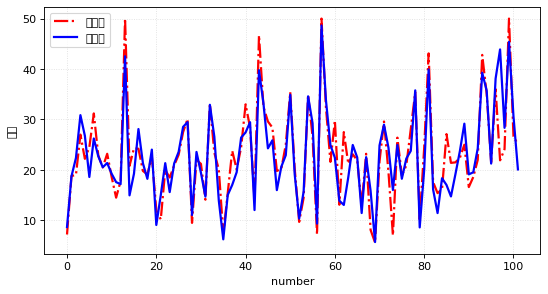

In [40]:
#绘图
import matplotlib.pyplot as plt

# 设置图形大小
plt.figure(figsize=(8, 4), dpi=80)
plt.plot(range(len(test_y)), test_y, ls='-.',lw=2,c='r',label='真实值')
plt.plot(range(len(pred_test_y)), pred_test_y, ls='-',lw=2,c='b',label='预测值')

# 绘制网格
plt.grid(alpha=0.4, linestyle=':')
plt.legend()
plt.xlabel('number') #设置x轴的标签文本
plt.ylabel('房价') #设置y轴的标签文本

# 展示
plt.show()

## 用RNN实现

In [45]:
from keras.layers import SimpleRNN, Dense

# 构建 RNN 模型
RNN_model = Sequential()
RNN_model.add(SimpleRNN(50, activation='relu', input_shape=(train_x.shape[1], 1)))
RNN_model.add(Dense(1))  # 输出层
RNN_model.compile(optimizer='adam', loss='mean_squared_error')

C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [47]:
# 训练模型
train_x = train_x.reshape(-1, train_x.shape[1], 1)
history = RNN_model.fit(train_x, train_y, epochs=100, batch_size=32, validation_split=0.2)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 143ms/step - loss: 602.2060 - val_loss: 634.5851
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 578.7812 - val_loss: 574.3002
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - loss: 449.9355 - val_loss: 110.5310
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 164.6248 - val_loss: 182.4562
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 165.5836 - val_loss: 105.7479
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - loss: 95.4311 - val_loss: 92.8455
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - loss: 78.0779 - val_loss: 91.4808
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 96.0412 - val_loss: 88.1669
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 71.6855 - val_loss: 82.5548
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 67.2143 - val_loss: 80.5203
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 71.0991 - val_loss: 87.9221
Epoch 12/100
11

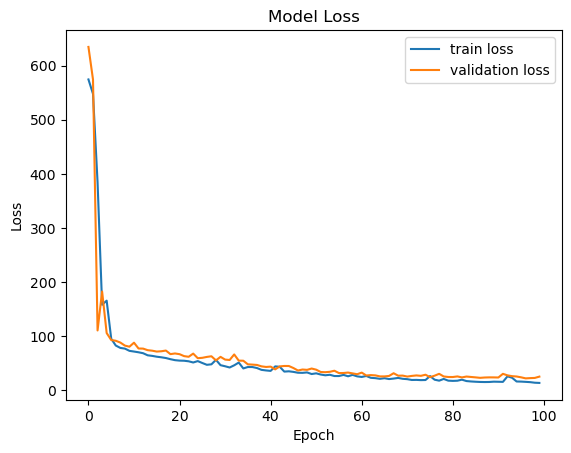

In [48]:
# 绘制损失曲线
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'],label='validation loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/stepWARNING:tensorflow:6 out of the last 321 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000022C3A82B240> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 287ms/step


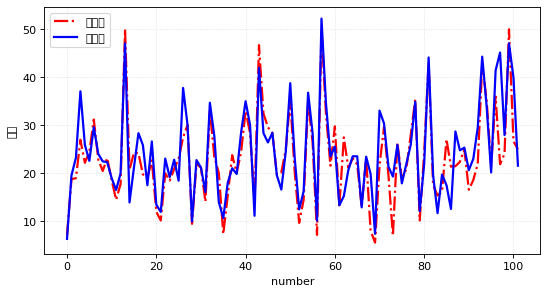

In [49]:
# 预测和绘图
test_x = test_x.reshape(-1, test_x.shape[1], 1)
pred_test_y = RNN_model.predict(test_x)

import matplotlib.pyplot as plt

# 设置图形大小
plt.figure(figsize=(8, 4), dpi=80)
plt.plot(range(len(test_y)), test_y, ls='-.',lw=2,c='r',label='真实值')
plt.plot(range(len(pred_test_y)), pred_test_y, ls='-',lw=2,c='b',label='预测值')

# 绘制网格
plt.grid(alpha=0.4, linestyle=':')
plt.legend()
plt.xlabel('number') #设置x轴的标签文本
plt.ylabel('房价') #设置y轴的标签文本

# 展示
plt.show()